# ECS 171 — Group 8: Memorization vs. Generalization

**Research topic:** Training-label randomization on UCI Dry Bean classification.  
**Assigned paper:** Zhang et al. (2017), *Understanding Deep Learning Requires Rethinking Generalization*.  
**Team:** Tianying Chen, Linjie Yang, and Elsey Chen.



In [18]:
# Import Libraries and Set Up the Experiment
# Import tools for downloading files and saving our results
from pathlib import Path
from urllib.request import urlretrieve
from zipfile import ZipFile
import json
import time
import warnings
# Libraries for data cleaning and numerical calculations
import numpy as np
import pandas as pd
# Libraries for creating plots and visualizing our data
import matplotlib.pyplot as plt
import seaborn as sns
# Save and load trained machine learning models
import joblib
# Split the dataset into training, validation, and test sets
from sklearn.model_selection import train_test_split
# Tools for data preprocessing and feature selection
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
# We will compare three different machine learning models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
# Metrics for evaluating and comparing model performance
from sklearn.metrics import (
    f1_score,
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)
# Handle convergence warnings during model training
from sklearn.exceptions import ConvergenceWarning
from IPython.display import display

# Use three random seeds to check if our results are consistent
SEEDS = [17, 29, 43]
# Test five levels of training-label randomization
NOISE_LEVELS = [0.0, 0.25, 0.50, 0.75, 1.0]
# Create a folder to save our results and figures
OUT = Path('outputs_notebook')
OUT.mkdir(exist_ok=True)
# Set the style for our plots
sns.set_theme(style='whitegrid')
# Check the experiment settings
print("Random seeds:", SEEDS)
print("Noise levels:", NOISE_LEVELS)
print("Total model fits:", len(SEEDS) * len(NOISE_LEVELS) * 3)


Random seeds: [17, 29, 43]
Noise levels: [0.0, 0.25, 0.5, 0.75, 1.0]
Total model fits: 45


## 1. Download the dataset

UCI Dry Bean contains 13,611 beans, 16 image-derived numerical characteristics, and seven varieties.

In [19]:
# Download the Dry Bean dataset from UCI
URL = 'https://archive.ics.uci.edu/static/public/602/dry+bean+dataset.zip'
# Create a folder to store the original dataset
RAW_DIR = Path('data/raw')
RAW_DIR.mkdir(parents=True, exist_ok=True)

zip_path = RAW_DIR / 'dry_bean_dataset.zip'
# Download the dataset if we have not downloaded it before
if not zip_path.exists():
    print('Downloading the original UCI Dry Bean dataset...')
    urlretrieve(URL, zip_path)
# Open the ZIP file and read the Excel dataset
with ZipFile(zip_path) as z:
    filename = next(name for name in z.namelist() if name.lower().endswith('.xlsx'))
    with z.open(filename) as f:
        df = pd.read_excel(f)
# Separate the 16 input features from the target variable (Class)
FEATURES = [c for c in df.columns if c != 'Class']
# Check the dataset size and display the first five rows
assert df.shape[1] == 17 and len(FEATURES) == 16

print('Original data dimensions:', df.shape)
display(df.head())


Original data dimensions: (13611, 17)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


## 2. Data cleaning

Before analyzing the data, we checked for missing values and duplicate rows. We found 68 duplicate rows and no missing values. We removed the duplicates to avoid having the same observations in both the training and test sets.


In [21]:
# Check for missing values and duplicates
audit = {
    'original_rows': len(df),
    'missing_cells': int(df.isna().sum().sum()),
    'duplicate_rows': int(df.duplicated().sum())
}
# Show the results
display(pd.DataFrame([audit]))
print('Data types:', df.dtypes.value_counts().to_dict())

# Remove duplicate rows
clean_df = df.drop_duplicates().reset_index(drop=True)

# Check if the cleaned data still has missing values or duplicates
assert clean_df.isna().sum().sum() == 0
assert not clean_df.duplicated().any()

print('Rows after cleaning:', len(clean_df))



,original_rows,missing_cells,duplicate_rows
0,13611,0,68


Data types: {dtype('float64'): 14, dtype('int64'): 2, <StringDtype(storage='python', na_value=nan)>: 1}
Rows after cleaning: 13543


The dataset originally had 13,611 rows. After removing 68 duplicates, we had 13,543 rows left. Since there were no missing values, we did not need to fill in any data.

## 3. Exploratory Data Analysis (EDA)

We first explored the dataset to better understand the different bean classes and their features. We looked at the number of samples in each class, compared some features using scatter plots, and checked the correlations between numerical features. These plots can help us understand the data before training our models.

,Count
Class,
DERMASON,3546
SIRA,2636
SEKER,2027
HOROZ,1928
CALI,1630
BARBUNYA,1322
BOMBAY,522


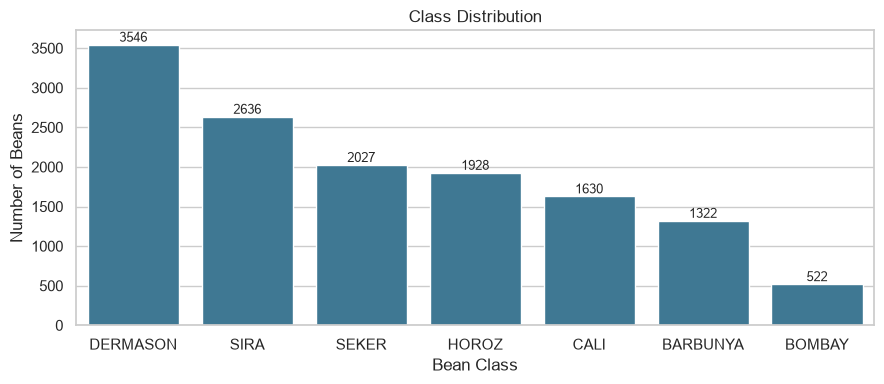

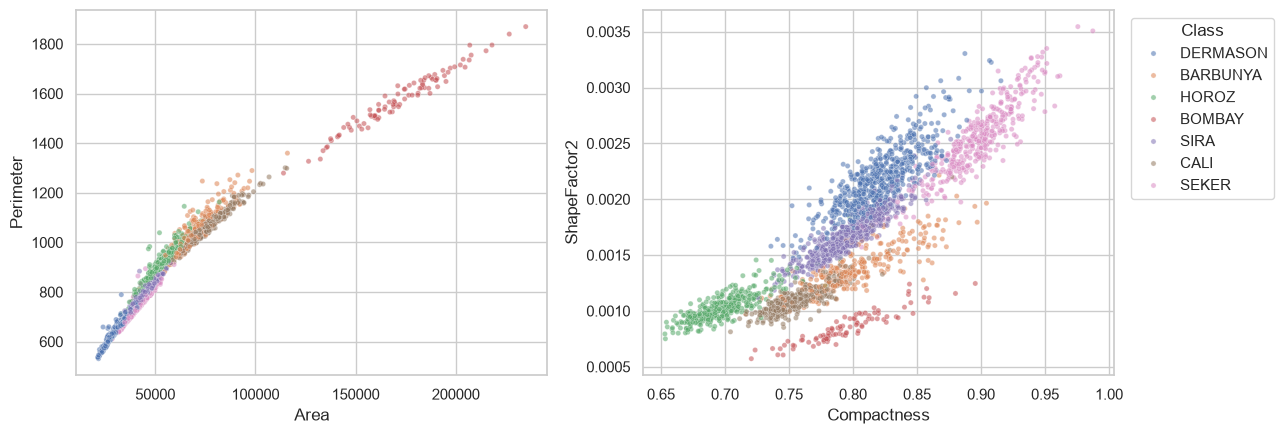

Area vs Perimeter Pearson correlation: 0.967


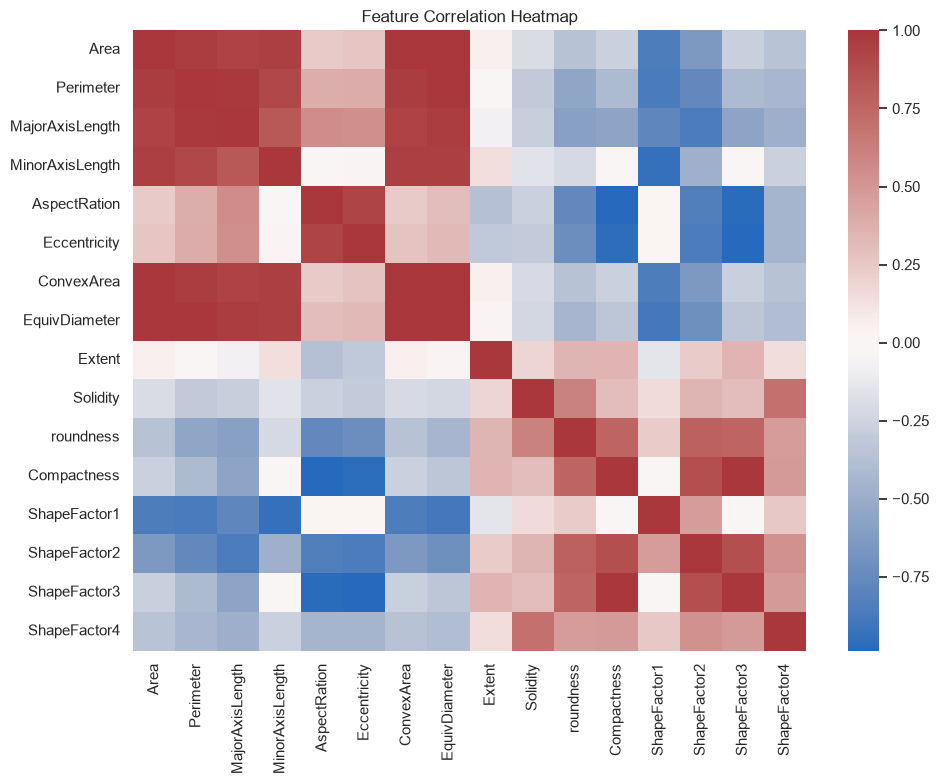

In [22]:
# Check how many beans belong to each class
class_counts = df['Class'].value_counts()
display(class_counts.rename('Count').to_frame())

# Plot the number of samples in each bean class
fig, ax = plt.subplots(figsize=(9, 4))

sns.barplot(
    x=class_counts.index,
    y=class_counts.values,
    color='#317da1',
    ax=ax
)

ax.set(
    title='Class Distribution',
    xlabel='Bean Class',
    ylabel='Number of Beans'
)

# Add the counts above each bar
for i, n in enumerate(class_counts.values):
    ax.text(i, n + 35, str(n), ha='center', fontsize=9)

fig.tight_layout()
fig.savefig(OUT / 'class_distribution.png', dpi=180)
plt.show()

# Use a sample of 2,500 beans to make the scatter plots easier to read
sample = clean_df.sample(n=min(2500, len(clean_df)), random_state=17)

# Compare some numerical features across different bean classes
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

feature_pairs = [
    ('Area', 'Perimeter'),
    ('Compactness', 'ShapeFactor2')
]

for ax, (x, y) in zip(axes, feature_pairs):
    sns.scatterplot(
        data=sample,
        x=x,
        y=y,
        hue='Class',
        s=14,
        alpha=0.55,
        ax=ax
    )

    if ax is axes[0]:
        ax.legend_.remove()

axes[1].legend(
    bbox_to_anchor=(1.02, 1),
    loc='upper left',
    title='Class'
)

fig.tight_layout()
fig.savefig(OUT / 'feature_relationships.png', dpi=180, bbox_inches='tight')
plt.show()


# Check the correlations between numerical features
correlations = clean_df[FEATURES].corr()

# Print the correlation between Area and Perimeter
print(
    'Area vs Perimeter Pearson correlation:',
    round(correlations.loc['Area', 'Perimeter'], 3)
)

# Create a heatmap to visualize feature correlations
fig, ax = plt.subplots(figsize=(10, 8))

sns.heatmap(
    correlations,
    cmap='vlag',
    center=0,
    ax=ax
)

ax.set_title('Feature Correlation Heatmap')

fig.tight_layout()
fig.savefig(OUT / 'feature_correlations.png', dpi=180)
plt.show()


# Save the summary statistics and class counts
clean_df[FEATURES].describe().to_csv(OUT / 'feature_summary.csv')
class_counts.to_csv(OUT / 'class_counts.csv')


### EDA Findings

The dataset has seven bean classes, but the number of samples is different for each class. DERMASON has the most samples (3,546), while BOMBAY has the fewest (522).

From the scatter plots, we can see that some bean classes have different shapes and sizes, although there is also overlap between classes.

We also found a strong positive correlation between Area and Perimeter (r = 0.967). This suggests that some features may contain similar information.

Since the classes are not balanced, we will use macro-F1 as our main evaluation metric when comparing the models.

## 4. Data Splitting and Preprocessing

We split the cleaned dataset into three parts: 70% for training, 15% for validation, and 15% for testing. We used stratified sampling to keep the proportion of each bean class similar across the three sets.

The training set will be used to train our models, the validation set will help us choose the best settings, and the test set will be used to evaluate the final results.

In [25]:
# Separate the input features and target labels
X = clean_df[FEATURES]
y = clean_df['Class']

# Split the data into 70% training and 30% remaining
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    stratify=y,
    random_state=17
)

# Split the remaining 30% equally into validation and test sets
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=17
)

# Get the names of the seven bean classes
classes = np.sort(y.unique())

# Check the number of samples in each set
print(
    'Train / Validation / Test:',
    len(X_train), len(X_val), len(X_test)
)

# Compare class proportions across the three sets
display(pd.DataFrame({
    'train': y_train.value_counts(normalize=True),
    'validation': y_val.value_counts(normalize=True),
    'test': y_test.value_counts(normalize=True)
}).round(3))


Train / Validation / Test: 9480 2031 2032


,train,validation,test
Class,,,
DERMASON,0.262,0.262,0.262
SIRA,0.195,0.194,0.195
SEKER,0.150,0.150,0.150
HOROZ,0.137,0.137,0.137
CALI,0.120,0.120,0.121
BARBUNYA,0.098,0.098,0.097
BOMBAY,0.039,0.038,0.038


### Data Splitting Results

After removing duplicates, we had 13,543 observations. We divided them into 9,480 training samples, 2,031 validation samples, and 2,032 test samples.

The class proportions are very similar across the three sets. For example, DERMASON makes up about 26.2% of each set. This shows that stratified sampling worked as expected.

We will only use the training data to fit preprocessing steps and train models, so information from the validation and test sets does not leak into training.

## 5. Model Selection and Feature Selection

We will compare three machine learning models for classifying dry beans:

- **Logistic Regression (LR):** A simple linear model that we can use as our baseline.
- **Random Forest (RF):** A tree-based model that can capture more complex relationships between features.
- **Multilayer Perceptron (MLP):** A neural network with two hidden layers (128 and 64 neurons).

We will also compare using all 16 features with selecting the 10 most useful features. For Logistic Regression and MLP, we will standardize the features before training. Random Forest does not require standardization.

We will try different model settings and use the validation set to choose the best ones.


In [26]:

# Define the three models we will use in our experiment
def build_model(name, config, seed=17):

    steps = []

    # Standardize features for Logistic Regression and MLP
    # Random Forest does not need feature scaling
    if name != 'RF':
        steps.append(('scaler', StandardScaler()))

    # Select the top features if we are using fewer than 16
    if config['k'] < len(FEATURES):
        steps.append((
            'feature_selection',
            SelectKBest(f_classif, k=config['k'])
        ))

    # Logistic Regression
    if name == 'LR':
        estimator = LogisticRegression(
            C=config['C'],
            max_iter=800,
            random_state=seed
        )

    # Random Forest with 200 trees
    elif name == 'RF':
        estimator = RandomForestClassifier(
            n_estimators=200,
            max_depth=config['depth'],
            min_samples_leaf=config['leaf'],
            random_state=seed,
            n_jobs=-1
        )

    # MLP with two hidden layers
    elif name == 'MLP':
        estimator = MLPClassifier(
            hidden_layer_sizes=(128, 64),
            alpha=config['alpha'],
            learning_rate_init=config['lr'],
            max_iter=180,
            early_stopping=False,
            random_state=seed
        )

    else:
        raise ValueError('Unknown model: ' + name)

    # Combine preprocessing and model training into one pipeline
    return Pipeline(steps + [('model', estimator)])


# Define different settings for hyperparameter tuning
def candidate_configs(name):

    # Compare using 10 features and all 16 features
    ks = [10, 16]

    # Try different regularization strengths for Logistic Regression
    if name == 'LR':
        return [
            {'k': k, 'C': c}
            for k in ks
            for c in [0.1, 1, 10]
        ]

    # Try different tree depths and minimum leaf sizes
    if name == 'RF':
        return [
            {'k': k, 'depth': d, 'leaf': leaf}
            for k in ks
            for d in [12, None]
            for leaf in [1, 3]
        ]

    # Try different regularization values for MLP
    if name == 'MLP':
        return [
            {'k': k, 'alpha': alpha, 'lr': 0.001}
            for k in ks
            for alpha in [0.0001, 0.01]
        ]

    raise ValueError('Unknown model: ' + name)


# Train a model while handling convergence warnings
def fit_without_warning(model, X, y):

    with warnings.catch_warnings():
        warnings.simplefilter('ignore', ConvergenceWarning)
        model.fit(X, y)

    return model


### Model Setup

We chose these three models because they use different approaches to classification. Logistic Regression will serve as a baseline, while Random Forest and MLP can learn more complex patterns.

We also included feature selection to see whether using fewer features improves model performance. We will compare different settings using the validation set before running the label randomization experiments.

## 6. Hyperparameter Tuning

Before testing different levels of label randomization, we need to find suitable settings for each model.

We will train each model using the original training labels and compare different hyperparameter settings on the validation set. We use macro-F1 to measure performance because the seven bean classes have different sample sizes.

For each model, we will choose the settings with the highest validation macro-F1 score. We will then use these settings in our label randomization experiments to make the comparisons fair.

We will not use the test set during hyperparameter tuning.

In [27]:

# Store the results of different hyperparameter settings
tuning_rows = []
# Store the best settings for each model
best_configs = {}
# Tune Logistic Regression, Random Forest, and MLP
for name in ['LR', 'RF', 'MLP']:

    best_val_score = -1

    # Try all the settings defined in Section 5
    for cfg in candidate_configs(name):

        # Build and train the model using clean training labels
        model = build_model(name, cfg)

        candidate = fit_without_warning(
            model,
            X_train,
            y_train
        )

        # Predict on the validation set
        y_pred = candidate.predict(X_val)

        # Calculate the validation macro-F1 score
        f1 = f1_score(
            y_val,
            y_pred,
            average='macro'
        )

        # Save the results for this setting
        tuning_rows.append({
            'model': name,
            'config': str(cfg),
            'validation_macro_f1': f1
        })

        # Update the best settings if the score is higher
        if f1 > best_val_score:
            best_val_score = f1
            best_configs[name] = cfg

    # Show the best settings for each model
    print(
        name,
        '| Best settings:', best_configs[name],
        '| Validation Macro-F1:', round(best_val_score, 4)
    )


# Put all tuning results into a DataFrame
tuning_df = pd.DataFrame(tuning_rows)

# Sort the results by model and validation score
tuning_df = tuning_df.sort_values(
    ['model', 'validation_macro_f1'],
    ascending=[True, False]
)

# Display the results
display(tuning_df)

# Save the tuning results for our report
tuning_df.to_csv(
    OUT / 'hyperparameter_tuning.csv',
    index=False
)


LR | Best settings: {'k': 16, 'C': 10} | Validation Macro-F1: 0.9312
RF | Best settings: {'k': 16, 'depth': 12, 'leaf': 1} | Validation Macro-F1: 0.9317
MLP | Best settings: {'k': 16, 'alpha': 0.01, 'lr': 0.001} | Validation Macro-F1: 0.9393


,model,config,validation_macro_f1
5,LR,"{'k': 16, 'C': 10}",0.931160
4,LR,"{'k': 16, 'C': 1}",0.931046
3,LR,"{'k': 16, 'C': 0.1}",0.929645
2,LR,"{'k': 10, 'C': 10}",0.920023
1,LR,"{'k': 10, 'C': 1}",0.917193
0,LR,"{'k': 10, 'C': 0.1}",0.905021
17,MLP,"{'k': 16, 'alpha': 0.01, 'lr': 0.001}",0.939291
16,MLP,"{'k': 16, 'alpha': 0.0001, 'lr': 0.001}",0.935324
14,MLP,"{'k': 10, 'alpha': 0.0001, 'lr': 0.001}",0.929313
15,MLP,"{'k': 10, 'alpha': 0.01, 'lr': 0.001}",0.928034


### Hyperparameter Tuning Results

We tested different hyperparameter settings for all three models using the validation set. For each model, we selected the settings that gave the highest macro-F1 score.

We also compared using 10 features and all 16 features to see whether feature selection improved performance.

The selected settings will be used for the next experiments, where we will study how training-label randomization affects model performance.

## 7. Training Label Randomization

In this part, we randomly change some of the training labels to see how this affects model performance.

We will test five randomization levels: 0%, 25%, 50%, 75%, and 100%. For each level, we randomly select training labels and assign them a new class from the seven bean classes.

The new label can sometimes be the same as the original one. We only change the training labels, while the validation and test labels stay unchanged.

This allows us to study whether models can fit random labels and how well they perform on new data.

In [29]:

# Randomly change a portion of the training labels
def randomize_train_labels(true_labels, p, seed, class_names):

    # Use a random seed so we can reproduce the results
    rng = np.random.default_rng(seed)

    # Make a copy to keep the original labels unchanged
    labels = np.asarray(true_labels).copy()

    # Randomly select which labels to change
    mask = rng.random(len(labels)) < p

    # Assign random classes to the selected labels
    labels[mask] = rng.choice(
        class_names,
        size=int(mask.sum()),
        replace=True
    )

    return labels


# Check that p=0 keeps all labels unchanged
original_labels = y_train.to_numpy()

test_labels = randomize_train_labels(
    y_train,
    0,
    17,
    classes
)

assert np.array_equal(test_labels, original_labels)

# Calculate the expected percentage of labels that actually change
expected_change = (len(classes) - 1) / len(classes)

print(
    'Expected changed-label fraction when p=1:',
    round(expected_change, 4)
)


Expected changed-label fraction when p=1: 0.8571


### Label Randomization

We tested the randomization function to make sure it works correctly. When p = 0, all training labels remain unchanged.

When p = 1, every training label is randomly assigned a class. Since there are seven possible classes, some labels may still match their original values. The expected percentage of labels that actually change is about 85.7%.

We will use the same randomization process for all three models so that we can compare their performance fairly.

## 8. Model Training and Evaluation

In this section, we will train our three models using different levels of label randomization.

We will test five randomization levels (0%, 25%, 50%, 75%, and 100%) with three random seeds (17, 29, and 43). This gives us 45 model training runs in total.

For each run, we will record the training accuracy, validation macro-F1, test macro-F1, accuracy, balanced accuracy, and training time.

We will compare the training accuracy on both randomized and original labels to see how well each model fits the training data. We will also evaluate the models on the clean test set to study their generalization performance.

All models will use the hyperparameters selected in Section 6.


In [30]:

# Store the results from all experiments
experiment_rows = []

# Save the models trained with original labels for our final demo
saved_clean_models = {}

# Run experiments with three random seeds
for seed in SEEDS:

    # Test five levels of label randomization
    for p in NOISE_LEVELS:

        # Randomize the training labels
        y_noisy = randomize_train_labels(
            y_train,
            p,
            seed,
            classes
        )

        # Check how many labels actually changed
        realized_change = np.mean(
            y_noisy != y_train.to_numpy()
        )

        # Train and evaluate each of the three models
        for name, cfg in best_configs.items():

            # Build the model using the selected hyperparameters
            model = build_model(name, cfg, seed)

            # Train the model and record the training time
            start = time.perf_counter()

            fit_without_warning(
                model,
                X_train,
                y_noisy
            )

            seconds = time.perf_counter() - start

            # Make predictions on the three datasets
            pred_train = model.predict(X_train)
            pred_val = model.predict(X_val)
            pred_test = model.predict(X_test)

            # Calculate different evaluation metrics
            record = {
                'model': name,
                'seed': seed,
                'noise_p': p,

                'actual_changed_fraction': realized_change,

                # Accuracy on the randomized training labels
                'train_accuracy_on_noisy_labels': accuracy_score(
                    y_noisy,
                    pred_train
                ),

                # Accuracy compared with the original training labels
                'train_accuracy_on_clean_labels': accuracy_score(
                    y_train,
                    pred_train
                ),

                # Validation performance
                'validation_macro_f1': f1_score(
                    y_val,
                    pred_val,
                    average='macro'
                ),

                # Test performance
                'test_macro_f1': f1_score(
                    y_test,
                    pred_test,
                    average='macro'
                ),

                'test_accuracy': accuracy_score(
                    y_test,
                    pred_test
                ),

                'test_balanced_accuracy': balanced_accuracy_score(
                    y_test,
                    pred_test
                ),

                # Training time
                'runtime_seconds': seconds
            }

            # Save the results from this experiment
            experiment_rows.append(record)

            # Keep models trained with original labels for the web demo
            if seed == 17 and p == 0:
                saved_clean_models[name] = model

            # Print the results of each training run
            print(
                f'{name} | Seed: {seed} | Noise: {p:.2f} | '
                f'Train Accuracy: {record["train_accuracy_on_noisy_labels"]:.3f} | '
                f'Test Macro-F1: {record["test_macro_f1"]:.3f}'
            )


# Convert all results into a DataFrame
results = pd.DataFrame(experiment_rows)

# Save the results as a CSV file
results.to_csv(
    OUT / 'all_experiments.csv',
    index=False
)

# Check that all 45 experiments were completed
print('Number of model fits:', len(results))

assert len(results) == 45

# Display the first five rows
display(results.head())


LR | Seed: 17 | Noise: 0.00 | Train Accuracy: 0.926 | Test Macro-F1: 0.942
RF | Seed: 17 | Noise: 0.00 | Train Accuracy: 0.985 | Test Macro-F1: 0.932
MLP | Seed: 17 | Noise: 0.00 | Train Accuracy: 0.951 | Test Macro-F1: 0.945
LR | Seed: 17 | Noise: 0.25 | Train Accuracy: 0.709 | Test Macro-F1: 0.919
RF | Seed: 17 | Noise: 0.25 | Train Accuracy: 0.799 | Test Macro-F1: 0.931
MLP | Seed: 17 | Noise: 0.25 | Train Accuracy: 0.742 | Test Macro-F1: 0.942
LR | Seed: 17 | Noise: 0.50 | Train Accuracy: 0.516 | Test Macro-F1: 0.913
RF | Seed: 17 | Noise: 0.50 | Train Accuracy: 0.638 | Test Macro-F1: 0.925
MLP | Seed: 17 | Noise: 0.50 | Train Accuracy: 0.547 | Test Macro-F1: 0.925
LR | Seed: 17 | Noise: 0.75 | Train Accuracy: 0.325 | Test Macro-F1: 0.906
RF | Seed: 17 | Noise: 0.75 | Train Accuracy: 0.587 | Test Macro-F1: 0.849
MLP | Seed: 17 | Noise: 0.75 | Train Accuracy: 0.363 | Test Macro-F1: 0.764
LR | Seed: 17 | Noise: 1.00 | Train Accuracy: 0.158 | Test Macro-F1: 0.171
RF | Seed: 17 | Noise

,model,seed,noise_p,actual_changed_fraction,train_accuracy_on_noisy_labels,train_accuracy_on_clean_labels,validation_macro_f1,test_macro_f1,test_accuracy,test_balanced_accuracy,runtime_seconds
0,LR,17,0.00,0.000000,0.925844,0.925844,0.931160,0.942302,0.929134,0.941606,0.242719
1,RF,17,0.00,0.000000,0.984599,0.984599,0.931712,0.932442,0.920276,0.929863,1.658689
2,MLP,17,0.00,0.000000,0.950527,0.950527,0.939291,0.944607,0.932579,0.943075,5.948707
3,LR,17,0.25,0.217511,0.709283,0.900422,0.915923,0.918952,0.899606,0.917009,0.553575
4,RF,17,0.25,0.217511,0.799156,0.942089,0.926104,0.931300,0.919291,0.929444,1.023684


### Initial Experimental Findings

We completed 45 model training runs using three models, five label randomization levels, and three random seeds.

From the initial results, we can see that increasing label randomization generally reduces test macro-F1. When the training labels are completely randomized, all three models perform much worse on the clean test set.

We also noticed that Random Forest can still achieve relatively high training accuracy on randomized labels, even when its test performance is low. This suggests that fitting noisy training labels does not necessarily lead to good generalization.

We will compare the average results across the three seeds in the next section.

## 9. Model Comparison and Visualization

After completing the 45 experiments, we will compare the performance of our three models at different levels of label randomization.

For each model and randomization level, we calculate the average performance across the three random seeds. We also calculate the standard deviation to see how much the results vary.

We will create three graphs:

1. Test macro-F1 at different randomization levels.
2. Training accuracy on randomized labels.
3. Training accuracy compared with the original labels.

These graphs will help us understand how label randomization affects model performance and whether models can fit noisy training data without generalizing well.


,model,noise_p,test_macro_f1_mean,test_macro_f1_sd,test_accuracy_mean,test_balanced_accuracy_mean,train_noisy_mean,train_clean_mean
0,LR,0.00,0.9423,0.0000,0.9291,0.9416,0.9258,0.9258
1,LR,0.25,0.9208,0.0025,0.9032,0.9188,0.7129,0.9014
2,LR,0.50,0.9149,0.0026,0.8971,0.9125,0.5193,0.8938
3,LR,0.75,0.9079,0.0018,0.8929,0.9045,0.3294,0.8927
4,LR,1.00,0.0976,0.0637,0.1027,0.1018,0.1597,0.1060
5,MLP,0.00,0.9436,0.0011,0.9321,0.9422,0.9498,0.9498
6,MLP,0.25,0.9413,0.0026,0.9300,0.9412,0.7450,0.9357
7,MLP,0.50,0.9246,0.0007,0.9167,0.9256,0.5487,0.9209
8,MLP,0.75,0.7960,0.0291,0.8237,0.8050,0.3643,0.8318
9,MLP,1.00,0.1264,0.0350,0.1394,0.1343,0.2750,0.1377


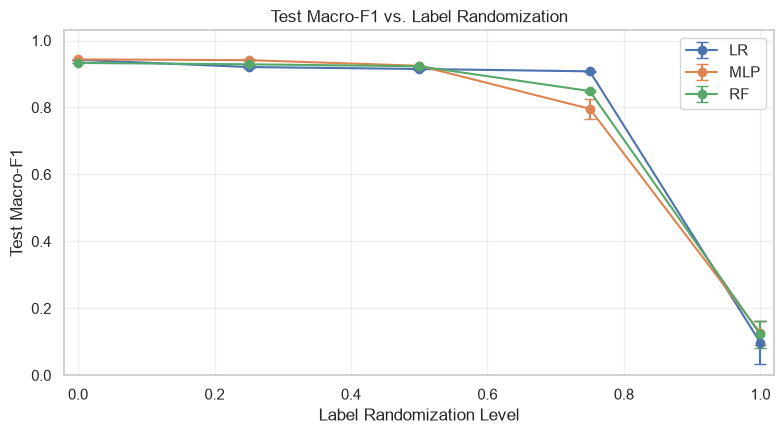

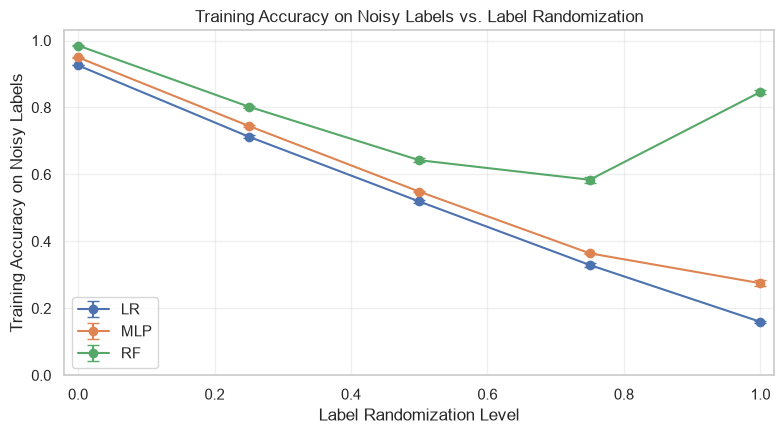

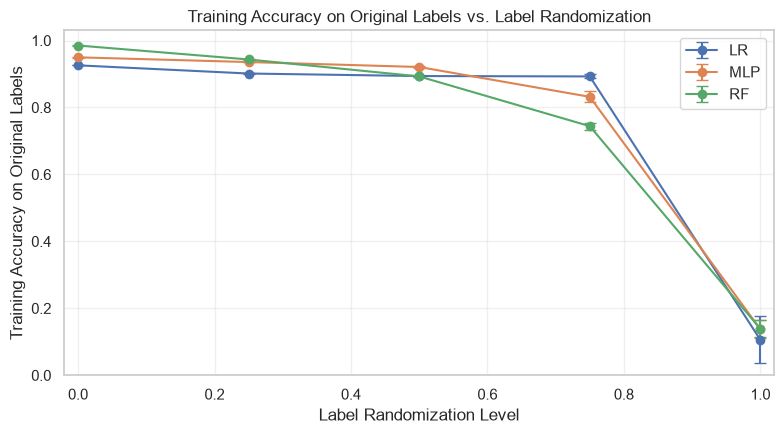

In [31]:

# Calculate the average results across the three random seeds
summary = results.groupby(
    ['model', 'noise_p'],
    as_index=False
).agg(
    test_macro_f1_mean=('test_macro_f1', 'mean'),
    test_macro_f1_sd=('test_macro_f1', 'std'),
    test_accuracy_mean=('test_accuracy', 'mean'),
    test_balanced_accuracy_mean=('test_balanced_accuracy', 'mean'),
    train_noisy_mean=('train_accuracy_on_noisy_labels', 'mean'),
    train_clean_mean=('train_accuracy_on_clean_labels', 'mean')
)

# Display the average results for each model and noise level
display(summary.round(4))

# Save the summary table
summary.to_csv(
    OUT / 'summary_by_noise.csv',
    index=False
)


# Create a function to plot model performance
def plot_metric(metric, ylabel, filename):

    fig, ax = plt.subplots(figsize=(8, 4.5))

    # Plot the results for each model
    for name, subset in results.groupby('model'):

        # Calculate the mean and standard deviation
        stats = subset.groupby('noise_p')[metric].agg(
            ['mean', 'std']
        ).sort_index()

        # Plot the mean with standard deviation error bars
        ax.errorbar(
            stats.index,
            stats['mean'],
            yerr=stats['std'],
            marker='o',
            capsize=4,
            label=name
        )

    # Add labels and title
    ax.set_title(ylabel + ' vs. Label Randomization')
    ax.set_xlabel('Label Randomization Level')
    ax.set_ylabel(ylabel)

    ax.set_xlim(-0.02, 1.02)
    ax.set_ylim(0, 1.03)

    ax.legend()
    ax.grid(alpha=0.3)

    # Save and display the figure
    fig.tight_layout()
    fig.savefig(OUT / filename, dpi=180)
    plt.show()


# Plot test macro-F1 for all three models
plot_metric(
    'test_macro_f1',
    'Test Macro-F1',
    'macro_f1_vs_noise.png'
)

# Plot training accuracy using randomized labels
plot_metric(
    'train_accuracy_on_noisy_labels',
    'Training Accuracy on Noisy Labels',
    'train_noisy_vs_noise.png'
)

# Plot training accuracy using original labels
plot_metric(
    'train_accuracy_on_clean_labels',
    'Training Accuracy on Original Labels',
    'train_clean_vs_noise.png'
)


### Model Comparison Findings

We compared Logistic Regression, Random Forest, and MLP using the average results from three random seeds.

**1. Effect of label randomization**

The results show that increasing label randomization generally reduces test macro-F1. When there is no randomization, all three models achieve macro-F1 scores above 0.93. However, when all training labels are randomly reassigned, their test performance drops significantly.

**2. Comparison between models**

MLP performs slightly better when there is little or no label randomization. However, Logistic Regression performs better when the randomization level reaches 75%. At this level, LR achieves a macro-F1 score of 0.908, compared with 0.849 for Random Forest and 0.796 for MLP.

This suggests that the simpler linear model may be more resistant to higher levels of label noise in our experiment.

**3. Memorization and generalization**

One interesting result is that Random Forest can still fit many randomized training labels. At 100% label randomization, its average training accuracy on noisy labels is about 0.846, while its test macro-F1 is only 0.122.

This shows that a model can fit training labels without performing well on new data. Our findings are consistent with the main idea discussed by Zhang et al. (2017).

Overall, our results suggest that different machine learning models respond differently to label randomization, and fitting training data does not always lead to good generalization.

## 10. Final Model Selection and Prediction

After comparing the three models, we will choose one model for our final prediction demo.

We will select the model with the highest validation macro-F1 score when using the original training labels. We will not use the test scores to choose the model.

We will then evaluate the selected model on the test set and create a confusion matrix to see how well it predicts each bean class.

Finally, we will save the trained model and test it on one observation. The saved model can also be used for our web-based demo.

Selected model: MLP
Classification Report:
              precision    recall  f1-score   support

    BARBUNYA       0.97      0.93      0.95       198
      BOMBAY       1.00      1.00      1.00        78
        CALI       0.93      0.96      0.94       245
    DERMASON       0.90      0.94      0.92       532
       HOROZ       0.96      0.96      0.96       279
       SEKER       0.96      0.96      0.96       304
        SIRA       0.91      0.85      0.88       396

    accuracy                           0.93      2032
   macro avg       0.95      0.94      0.94      2032
weighted avg       0.93      0.93      0.93      2032



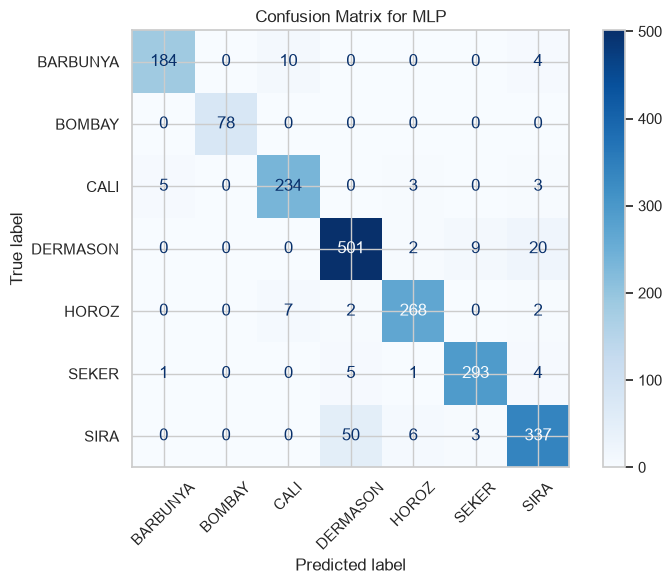

Model saved successfully.
Predicted bean class: SEKER
Actual bean class: SEKER


,Class,Predicted Probability
5,SEKER,9.963134e-01
3,DERMASON,3.682904e-03
6,SIRA,3.250978e-06
4,HOROZ,2.495689e-07
2,CALI,1.630428e-07
1,BOMBAY,9.316596e-09
0,BARBUNYA,8.146695e-10


In [32]:

# Select models trained with the original labels
clean_candidates = results[
    (results['seed'] == 17) &
    (results['noise_p'] == 0)
]

# Find the model with the highest validation macro-F1
best_name = clean_candidates.sort_values(
    'validation_macro_f1',
    ascending=False
).iloc[0]['model']

# Get the selected trained model
best_model = saved_clean_models[best_name]

print('Selected model:', best_name)


# Evaluate the selected model on the test set
test_prediction = best_model.predict(X_test)

# Show precision, recall, and F1-score for each class
print('Classification Report:')
print(classification_report(y_test, test_prediction))


# Create a confusion matrix
fig, ax = plt.subplots(figsize=(8, 6))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_prediction,
    labels=classes,
    xticks_rotation=45,
    cmap='Blues',
    ax=ax
)

ax.set_title('Confusion Matrix for ' + best_name)

fig.tight_layout()

# Save the confusion matrix
fig.savefig(
    OUT / 'best_clean_confusion_matrix.png',
    dpi=180
)

plt.show()


# Save the selected model for future predictions
joblib.dump(
    best_model,
    OUT / 'best_model.joblib'
)


# Save some information about the selected model
best_val_f1 = clean_candidates.set_index('model').loc[
    best_name, 'validation_macro_f1'
]

metadata = {
    'model': best_name,
    'validation_macro_f1': float(best_val_f1),
    'classes': classes.tolist(),
    'trained_on': 'clean training labels'
}

(OUT / 'best_model_metadata.json').write_text(
    json.dumps(metadata, indent=2)
)

print('Model saved successfully.')


# Test the model using one observation from the test set
one_bean = X_test.iloc[[0]]

# Predict the bean class
prediction = best_model.predict(one_bean)[0]

print('Predicted bean class:', prediction)
print('Actual bean class:', y_test.iloc[0])


# Show the predicted probability for each class
if hasattr(best_model, 'predict_proba'):

    probabilities = best_model.predict_proba(one_bean)[0]

    probability_table = pd.DataFrame({
        'Class': best_model.classes_,
        'Predicted Probability': probabilities
    })

    # Sort the classes by predicted probability
    probability_table = probability_table.sort_values(
        'Predicted Probability',
        ascending=False
    )

    display(probability_table)



### Final Model Evaluation

We selected MLP as our final model based on its validation performance. On the test set, the model achieved an accuracy of about 93% and a macro-F1 score of 0.94.

From the confusion matrix, we can see that the model performs well on most bean classes. BOMBAY has the best performance, with all 78 test samples classified correctly. However, SIRA is more difficult to classify. Its F1-score is 0.88, and 50 SIRA samples were incorrectly predicted as DERMASON.

We also tested the model on one sample from the test set. The model predicted SEKER, which matched the actual class. The predicted probability for SEKER was about 99.63%.

Finally, we saved the trained model so that we can use it for our web-based demo.